#  Reconstruction of Octant Convergence Maps from Shear

In [1]:
import numpy as np
import healpy as hp
import healsparse as hsp
import os
from astropy.io import fits
import matplotlib.pyplot as plt

In [2]:
def radec2thetaphi(ra, dec):
    """
    Convert ra and dec (in degrees) to theta and phi (Healpix conventions, in radians)

    """
    theta = np.pi / 2. - np.deg2rad(dec)
    phi = np.deg2rad(ra)
    return theta, phi

def make_mask_radec_cuts(nside, ramin, ramax, decmin, decmax, eps=0., dtype=float, nest=True):
    """Generate a square mask limited by RA/DEC

    Parameters
    ----------
    nside : int
        `nside` parameter for healpix.
    ramin, ramax : float
        Should be in degrees in [0., 360.]
    decmin, decmax: [type]
        Should be in degrees in [-90., +90.]

    Returns
    -------
    array
        Returns the square mask.
    """
    # Make sure arguments are correct
    assert (0. <= ramin <= 360.) & (0. <= ramax <= 360.) & (ramin < ramax)
    assert (-90. <= decmin <= 90.) & (-90. <= decmax <= 90.) & (decmin < decmax)

    mask = np.zeros(hp.nside2npix(nside))
    th, ph = hp.pix2ang(nside, np.arange(hp.nside2npix(nside)), nest=nest)
    ths, phs = radec2thetaphi([ramin, ramax], [decmin, decmax])
    thmin, thmax = min(ths), max(ths)
    phmin, phmax = min(phs), max(phs)
    mask[np.where((th < thmax-eps) & (th > thmin+eps) & (ph > phmin+eps) & (ph < phmax-eps))[0]] = dtype(1)
    return mask

In [3]:
# path = "/pscratch/sd/j/jmena/HOS_Sims"
path = os.path.join(os.environ["CFS"], "lsst/shared/external/HACC-HOS-Y1/HOS_Sims")

In [4]:
sim_seed = "HACC150_3" # whichever
Nshells = 51
seed = 0
imap = 4 # from 0 to 4
nside = 8192

catalog_filename = os.path.join(path, f"{sim_seed}/shells_z{Nshells}_subsampledensitymax1.5_nside{nside}/SRDv1_nz/kappa_hacc_seed{seed}_nside{nside}_catpoisson_interppixels_b1_imap{imap}.fits")
catalog = fits.open(catalog_filename)
cat = catalog[1].data

In [5]:
catalog.info()

Filename: /global/cfs/cdirs/lsst/shared/external/HACC-HOS-Y1/HOS_Sims/HACC150_3/shells_z51_subsampledensitymax1.5_nside8192/SRDv1_nz/kappa_hacc_seed0_nside8192_catpoisson_interppixels_b1_imap4.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     38   111389654R x 10C   ['E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E', 'E']   


In [6]:
catalog[1].columns

ColDefs(
    name = 'ra'; format = 'E'
    name = 'dec'; format = 'E'
    name = 'z'; format = 'E'
    name = 'chi'; format = 'E'
    name = 'kappa'; format = 'E'
    name = 'gamma1'; format = 'E'
    name = 'gamma2'; format = 'E'
    name = 't11'; format = 'E'
    name = 't12'; format = 'E'
    name = 't22'; format = 'E'
)

In [7]:
catalog_new={'ra': cat['ra'], 'dec':cat['dec'],'z':cat['z'],'g1': cat['gamma1'], 'g2': cat['gamma2']}

In [8]:
# ---------------------------------
# Read galaxy catalog
# ---------------------------------

with fits.open(catalog_filename, memmap=True) as hdul:
    data = hdul[1].data

    ra = np.asarray(data["RA"], dtype=np.float64)
    dec = np.asarray(data["DEC"], dtype=np.float64)

    gamma1 = np.asarray(data["gamma1"], dtype=np.float64)
    gamma2 = np.asarray(data["gamma2"], dtype=np.float64)

    if "weight" in data.names:
        weight = np.asarray(data["weight"], dtype=np.float64)
    else:
        weight = np.ones_like(gamma1)


In [9]:
# ---------------------------------
# Remove invalid entries
# ---------------------------------

valid = (
    np.isfinite(ra)
    & np.isfinite(dec)
    & np.isfinite(gamma1)
    & np.isfinite(gamma2)
    & np.isfinite(weight)
    & (dec >= -90)
    & (dec <= 90)
    & (weight > 0)
)

ra = ra[valid]
dec = dec[valid]
gamma1 = gamma1[valid]
gamma2 = gamma2[valid]
weight = weight[valid]

In [10]:
# ---------------------------------
# Convert coordinates to pixels
# ---------------------------------

nside_out = 2048  # Desired resolution

pix = hp.ang2pix(nside_out, ra, dec,lonlat=True,nest=False)

npix = hp.nside2npix(nside_out)

In [11]:
# ---------------------------------
# Accumulate weighted shear
# ---------------------------------

sum_w = np.bincount(pix, weights=weight, minlength=npix)
sum_g1 = np.bincount(pix, weights=weight * gamma1, minlength=npix)
sum_g2 = np.bincount(pix, weights=weight * gamma2, minlength=npix)

count = np.bincount(pix, minlength=npix)

In [12]:
# ---------------------------------
# Compute mean shear
# ---------------------------------

gamma1_low = np.full(npix, hp.UNSEEN)
gamma2_low = np.full(npix, hp.UNSEEN)

observed = sum_w > 0

gamma1_low[observed] = sum_g1[observed] / sum_w[observed]
gamma2_low[observed] = sum_g2[observed] / sum_w[observed]


In [13]:
# ---------------------------------
# Save maps
# ---------------------------------

hp.write_map(f"gamma1_{nside_out}.fits", gamma1_low,nest=False, overwrite=True, dtype=np.float32)

hp.write_map(f"gamma2_{nside_out}.fits", gamma2_low, nest=False, overwrite=True, dtype=np.float32)

hp.write_map(f"galaxy_count_{nside_out}.fits", count, nest=False, overwrite=True, dtype=np.int32)

print("NSIDE:", nside_out)
print("Total galaxies:", len(ra))
print("Observed pixels:", np.count_nonzero(observed))


NSIDE: 2048
Total galaxies: 111389654
Observed pixels: 6293498


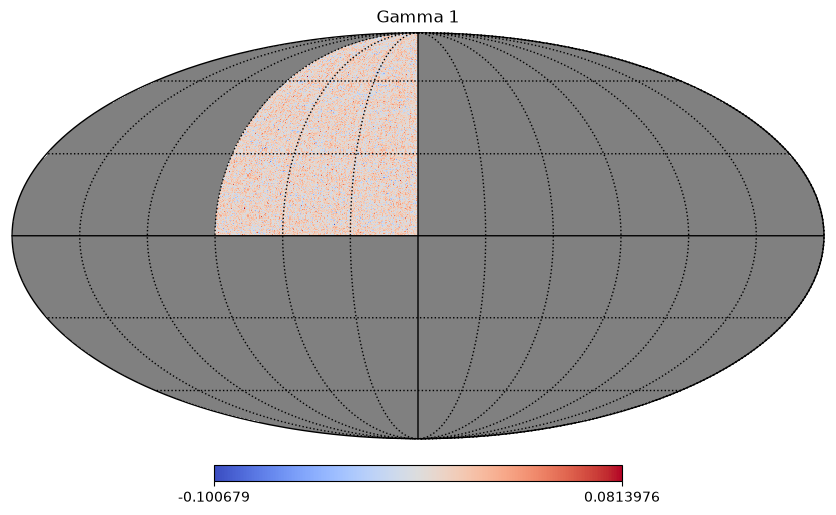

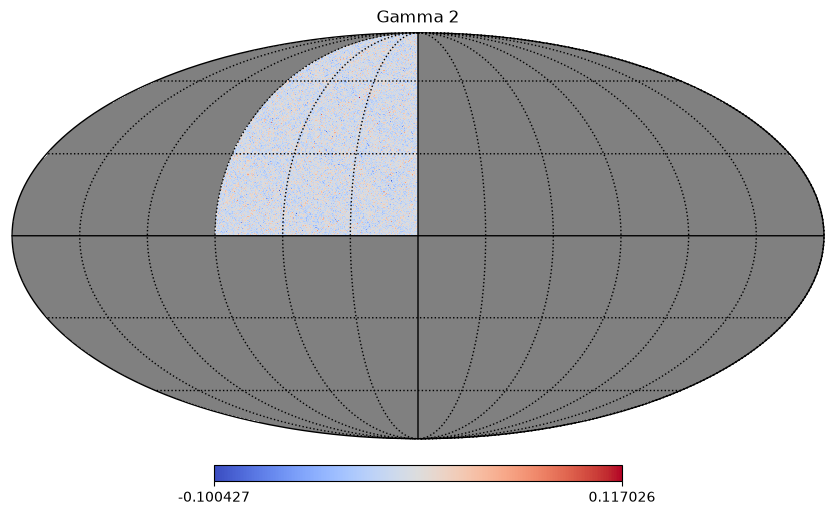

In [14]:
# ---------------------------------
# Visualize
# ---------------------------------

# Close previous figures
plt.close('all')

# Disable LaTeX BEFORE plotting
plt.rcParams['text.usetex'] = False

# Gamma 1
hp.mollview(gamma1_low, title="Gamma 1", cmap="coolwarm")
hp.graticule()

# Gamma 2
hp.mollview(gamma2_low, title="Gamma 2", cmap="coolwarm")
hp.graticule()

plt.show()

In [15]:
def shear_to_kappa(gamma1, gamma2):

    nside = hp.npix2nside(gamma1.size)
    lmax = 3 * nside - 1

    # Identify valid pixels
    valid = (
        np.isfinite(gamma1)
        & np.isfinite(gamma2)
        & (gamma1 != hp.UNSEEN)
        & (gamma2 != hp.UNSEEN)
    )

    # Replace missing pixels with zero
    g1 = np.where(valid, gamma1, 0.0)
    g2 = np.where(valid, gamma2, 0.0)

    # Spherical harmonic transformation
    elm, blm = hp.map2alm_spin([g1, g2],spin=2,lmax=lmax)

    ell = np.arange(lmax + 1)

    f = np.zeros(lmax + 1)

    good = ell >= 2

    f[good] = -np.sqrt(ell[good] * (ell[good] + 1) /((ell[good] + 2) * (ell[good] - 1)))

    # Reconstruct convergence
    kappa_E = hp.alm2map(hp.almxfl(elm, f), nside, lmax=lmax)

    kappa_B = hp.alm2map(hp.almxfl(blm, f), nside, lmax=lmax)

    return kappa_E, kappa_B

In [16]:
kappa_E, kappa_B = shear_to_kappa(gamma1_low, gamma2_low)

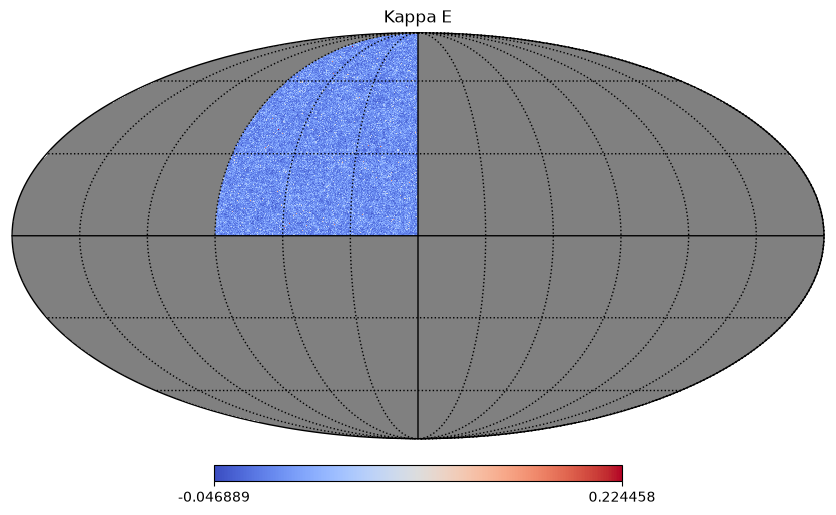

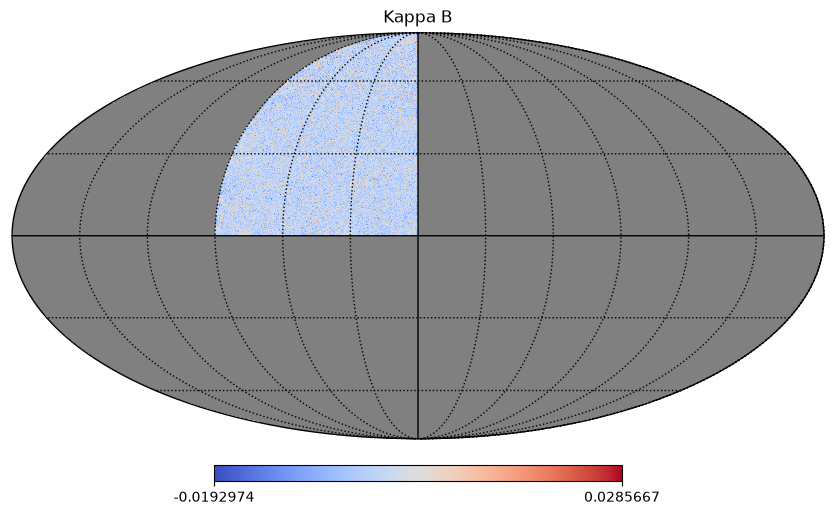

In [17]:
kappa_E_plot = kappa_E.copy()
kappa_B_plot = kappa_B.copy()

kappa_E_plot[~observed] = hp.UNSEEN
kappa_B_plot[~observed] = hp.UNSEEN

hp.mollview(kappa_E_plot, title="Kappa E", cmap="coolwarm")
hp.graticule()

hp.mollview(kappa_B_plot, title="Kappa B", cmap="coolwarm")
hp.graticule()

plt.show()

In [18]:
mask_octant = make_mask_radec_cuts(nside_out, 0, 90, 0, 90, eps=1e-10, nest=False)
mask_indices = np.where(mask_octant==1)

In [19]:
kappa_octant = np.full_like(kappa_E,hp.UNSEEN )
kappa_octant[mask_indices]= kappa_E[mask_indices]

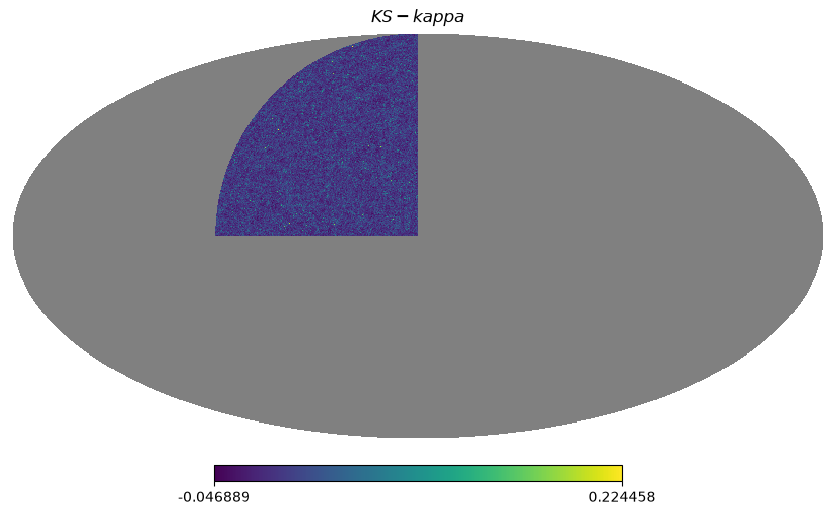

In [20]:
# Plot E-mode convergence
hp.mollview(kappa_octant,title = "$KS-kappa$")

#hp.graticule()
plt.show()

In [21]:
hp.write_map(f"kappa_KS_octant_{imap}.fits", kappa_octant, nest=False, overwrite=True,dtype=np.float32)